# DATA-500: Homework Assignment 7

## Instructions

- This homework assignment is worth **82** points. 
- Please strive for clarity and organization.
- **AI Usage**:
   - AI use is strictly **prohibited** for conceptual exercises.
   - For applied (Python) exercises, you may only use AI for **debugging**. Do not use AI to generate answers.
- **Due Date: November 7, 2026, by 11:59 PM.**

# Exercise 1 

In this exercise, we will focus on testing code in analytics/data science tasks. Consider the following scenario. You are working with transactional sales data, and want to compute statistics such as total sales, average sales, and identify outliers. The task is to write functions for these calculations and test them.

### Exercise 1(a) (4 points)

Create a function called `calculate_total_sales(sales_list)` that:

- Takes a list of numbers representing sales transactions.
- Returns the total sales amount (sum of all values in `sales_list`).

In [1]:

def calculate_total_sales(sales_list):
    return sum(sales_list)


sales = [100, 200, 150, 50, 300]

total = calculate_total_sales(sales)

print("Total Sales:", total)


Total Sales: 800


### Exercise 1(b) (6 points)

Create a function called `test_calculate_total_sales(sales_list)` that:

- Test if the input is a list.
- Test with an empty list (should return `0`).
- Test with a list containing one transaction.
- Test with a list of multiple transactions.

In [34]:

def test_calculate_total_sales(sales_list):
    assert isinstance(sales_list, list), "Input must be a list"

    assert calculate_total_sales([]) == 0

    assert calculate_total_sales([100]) == 100

    assert calculate_total_sales([100, 200, 300]) == 600

    print("All tests passed!")

test_calculate_total_sales([100, 200, 300])


All tests passed!


### Exercise 1(c) (4 points)

Create a function called `calculate_average_sales(sales_list)` function that:

- Takes a list of sales transactions.
- Returns the average sales amount. If `sales_list` is empty, return `0`.

In [33]:

def calculate_average_sales(sales_list):
    if len(sales_list) == 0:
        return 0

    return sum(sales_list) / len(sales_list)

sales = [100, 200, 150, 50, 300]

average = calculate_average_sales(sales)

print("Average Sales:", average)


Average Sales: 160.0


### Exercise 1(d) (6 points)

Create a function called `test_calculate_average_sales(sales_list)` that:

- Test if the input is a list.
- Test with an empty list (should return `0`).
- Test with a list containing one transaction.
- Test with a list of multiple transactions.

In [32]:

def test_calculate_average_sales(sales_list):
    assert isinstance(sales_list, list), "Input must be a list"

    assert calculate_average_sales([]) == 0

    assert calculate_average_sales([100]) == 100

    assert calculate_average_sales([100, 200, 300]) == 200

    print("All tests passed!")

test_calculate_average_sales([100, 200, 300])


All tests passed!


### Exercise 1(e) (6 points)

Create a function called `identify_outliers(sales_list, threshold=1.5)` that:

- Identifies any transaction that is above `threshold * mean` as an outlier.
- Returns a list of outliers.

Notice that you need to use `calculate_average_sales` from part 1(c) to compute the average.

In [31]:

def identify_outliers(sales_list, threshold=1.5):
    mean = calculate_average_sales(sales_list)

    outliers = []

    for sale in sales_list:
        if sale > threshold * mean:
            outliers.append(sale)

    return outliers

sales = [100, 200, 150, 50, 300]

result = identify_outliers(sales)

print("Outliers:", result)


Outliers: [300]


### Exercise 1(f) (6 points)

Create a function called `test_identify_outliers(sales_list, threshold=1.5)` that:

- Test with no outliers.
- Test with one or more outliers.
- Test with an empty list.

In [30]:

def test_identify_outliers(sales_list, threshold=1.5):
    assert identify_outliers([100, 100, 100], threshold) == []

    assert identify_outliers([100, 100, 100, 300], threshold) == [300]

    assert identify_outliers([100, 100, 300, 400], threshold) == [400]

    assert identify_outliers([], threshold) == []

    print("All tests passed!")


test_identify_outliers([100, 200, 300])


All tests passed!


# Exercise 2 

In this exercise, we will explore the `powerconsumption.csv` data file. The data consists of 52,416 observations of energy consumption on a 10-minute window. Every observation is described by 9 feature columns. Here is a brief description of each of the columns:

- `Datetime`: Time window of ten minutes.
- `Temperature`: Weather Temperature.
- `Humidity`: Weather Humidity.
- `WindSpeed`: Wind Speed.
- `GeneralDiffuseFlows`: “Diffuse flow” is a catchall term to describe low-temperature (< 0.2° to ~ 100°C) fluids that slowly discharge through sulfide mounds, fractured lava flows, and assemblages of bacterial mats and macrofauna.
- `DiffuseFlows`
- `PowerConsumption_Zone1`
- `PowerConsumption_Zone2`
- `PowerConsumption_Zone3`

For more information about the data, see this [link](https://www.kaggle.com/datasets/fedesoriano/electric-power-consumption).

### Exercise 2(a) (2 points)

Load `pandas`, `matplotlib`, and `seaborn`


In [9]:

import micropip
await micropip.install("seaborn")


In [10]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


### Exercise 2(b) (2 points)

Read the `powerconsumption.csv` data file and create a data frame called `df`.

In [29]:

df = pd.read_csv("powerconsumption.csv")

df.head()


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


### Exercise 2(c) (3 points)

Convert `Datetime` to date-time format. 

In [28]:

df["Datetime"] = pd.to_datetime(
    df["Datetime"],
    format="%m/%d/%Y %H:%M"
)

print(df["Datetime"].dtype)


datetime64[us]


### Exercise 2(d) (8 points)

Create a time-series plot that shows how `Temperature` and `Humidity` evolve with time.

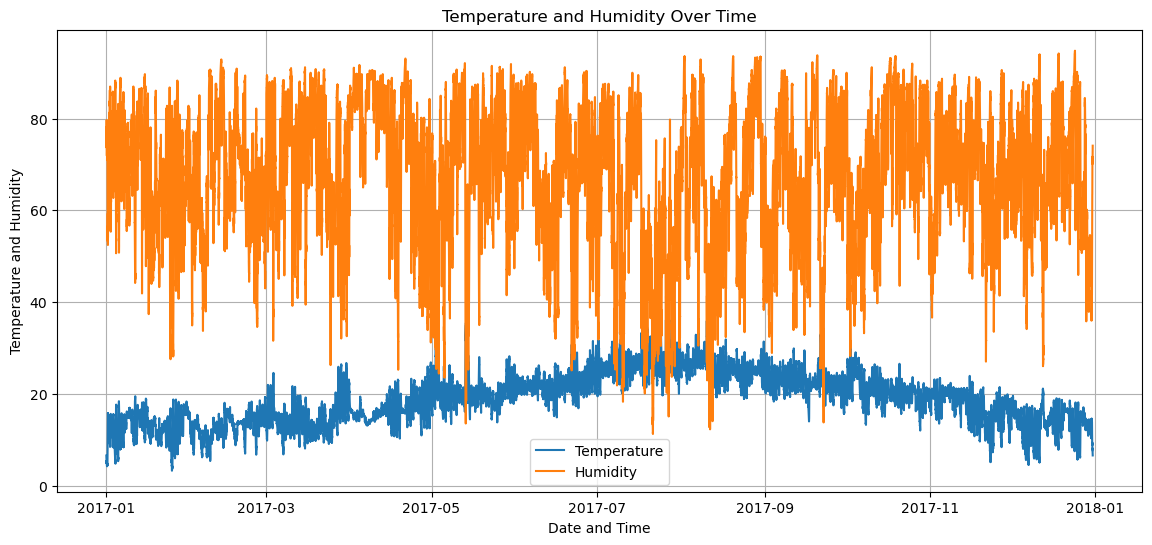

In [27]:

plt.figure(figsize=(14, 6))

plt.plot(df["Datetime"], df["Temperature"], label="Temperature")

plt.plot(df["Datetime"], df["Humidity"], label="Humidity")

plt.xlabel("Date and Time")
plt.ylabel("Temperature and Humidity")
plt.title("Temperature and Humidity Over Time")

plt.legend()
plt.grid(True)

plt.show()


### Exercise 2(e) (6 points)

Create a scatter-plot of `Temperature` and `Humidity`. Describe the chart.

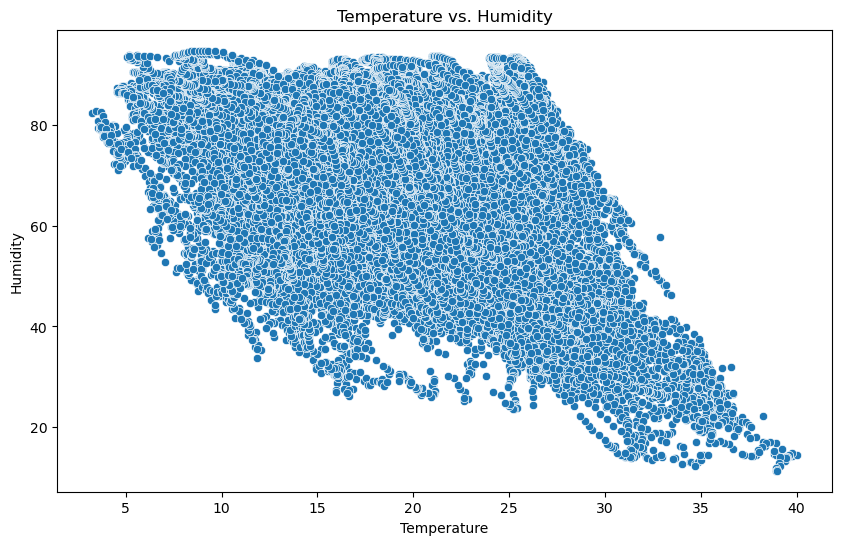

In [26]:

plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x="Temperature", y="Humidity")

plt.xlabel("Temperature")
plt.ylabel("Humidity")
plt.title("Temperature vs. Humidity")

plt.show()


The scatter plot shows the relationship between temperature and humidity. Each point represents an observation in the dataset. The chart helps us see whether changes in temperature are associated with changes in humidity. We can also use the chart to identify patterns, clusters, and unusual observations.

### Exercise 2(f) (5 points)

Create two columns in the `df` data-frame called:

- `Date`: extract the date (wihout time) from `Datetime` and store it in this column.
- `Day`: extract the day (three letter abbrevation) from `Datetime` and store it in this column.

In [25]:

df["Date"] = df["Datetime"].dt.date

df["Day"] = df["Datetime"].dt.strftime("%a")

df[["Datetime", "Date", "Day"]].head()


,Datetime,Date,Day
0,2017-01-01 00:00:00,2017-01-01,Sun
1,2017-01-01 00:10:00,2017-01-01,Sun
2,2017-01-01 00:20:00,2017-01-01,Sun
3,2017-01-01 00:30:00,2017-01-01,Sun
4,2017-01-01 00:40:00,2017-01-01,Sun


### Exercise 2(g) (8 points)

Create a data-frame called `df_date_mean`. This data-frame should contains the average `Temperature` and average `Humidity` based on `Date`. Then, create a scatter plot of `Temperature` and `Humidity`. Describe the plot.

In [24]:

df_date_mean = df.groupby("Date")[["Temperature", "Humidity"]].mean().reset_index()

df_date_mean.head()


,Date,Temperature,Humidity
0,2017-01-01,9.675299,68.519306
1,2017-01-02,12.476875,71.456319
2,2017-01-03,12.100000,74.981667
3,2017-01-04,10.509479,75.459792
4,2017-01-05,10.866444,71.040486


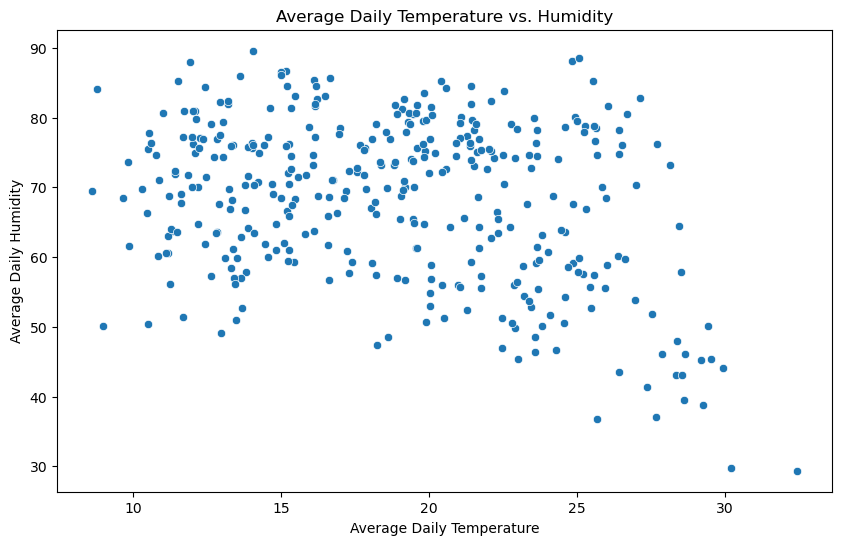

In [23]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_date_mean,
    x="Temperature",
    y="Humidity"
)

plt.xlabel("Average Daily Temperature")
plt.ylabel("Average Daily Humidity")
plt.title("Average Daily Temperature vs. Humidity")

plt.show()


The scatter plot shows the relationship between average daily temperature and average daily humidity. Each point represents the average values for one day. By calculating daily averages, the chart reduces the variation from individual 10-minute observations and makes the overall relationship between temperature and humidity easier to see.

### Exercise 2(h) (6 points)

Create a data-frame called `df_day_mean`. This data-frame should contains the average `Temperature` and average `Humidity` based on `Day`. What is the day of the week with the highest average `Temperature`? What is the day of the week with the highest average `Humidity`?

In [22]:

df_day_mean = df.groupby("Day")[["Temperature", "Humidity"]].mean().reset_index()

df_day_mean


,Day,Temperature,Humidity
0,Fri,19.083073,66.274296
1,Mon,18.784243,69.644225
2,Sat,18.611271,68.546046
3,Sun,18.538161,69.161163
4,Thu,18.834958,67.476703
5,Tue,18.865114,68.928942
6,Wed,18.953348,67.785254


In [21]:

highest_temp_day = df_day_mean.loc[df_day_mean["Temperature"].idxmax(), "Day"]

highest_humidity_day = df_day_mean.loc[df_day_mean["Humidity"].idxmax(), "Day"]

print("Day with highest average Temperature:", highest_temp_day)
print("Day with highest average Humidity:", highest_humidity_day)


Day with highest average Temperature: Fri
Day with highest average Humidity: Mon


Based on the average temperature and humidity for each day of the week, Friday has the highest average temperature at approximately 19.08°C. Monday has the highest average humidity at approximately 69.64%.

# Exercise 3

In this exercise, we will review some of the concepts about testing code.

### Exercise 3(a) (4 points)

A colleague writes a function, runs it on a sample input, sees that it returns `2.87`, and then writes the test `assert result == 2.87`. Which of the following best explains why this is a poor testing practice?

- **A.** The test will run too slowly because it uses a hard-coded number.
- **B.** The test only verifies that the code still does what it currently does, including any bug it currently has.
- **C.** Tests should never use `assert` statements.
- **D.** The test is not necessary because the function already ran without errors.

B

### Exercise 3(b) (6 points)

When a function receives invalid input (e.g., an empty list), it can either return a sentinel value such as `None` or raise an exception such as `ValueError`. Describe one advantage and one disadvantage of each approach. Then, state which approach you would use inside an analytical function that is part of a reusable library, and why.

Returning `None`:

- Advantage: The program can keep running even if something is wrong.
- Disadvantage: You might not notice that something went wrong.

Raising an Exception (`ValueError`):

- Advantage: It lets you know right away that something is wrong.
- Disadvantage: It can stop the program if the error isn't handled.

My Preference:

I would use `ValueError` because I think it's better to know when something is wrong rather than have the program continue with a mistake. This would also make it easier for other people using the code to find and fix problems.